# Tome 2, Appendix L: Linear Dynamics (Python companion)

Exercises first, solutions at the end. We watch Gelfand's formula converge (slowly), measure transient growth, solve Lyapunov equations, race gradient descent against Chebyshev, the heavy ball and conjugate gradients, steer a cart with the minimal-energy control, and test Maxwell's criterion on random cubics. We use `numpy`, `scipy`, `matplotlib` and the standard library.

*Before each solution, predict what the output will look like.*

In [1]:
import math
import numpy as np
import scipy.linalg
import scipy.integrate
import matplotlib.pyplot as plt
rng = np.random.default_rng(12)

## Exercises

**P12.1 (★) Gelfand's formula and transient growth.** For a random $6\times6$ matrix and for the matrix of Figure 12.1, plot $\|A^k\|_2^{1/k}$ against $k$ together with $\rho(A)$ (Theorem 12.3). Then, for $A_c=\bigl(\begin{smallmatrix}0.9&c\\0&0.9\end{smallmatrix}\bigr)$, compute $\max_k\|A_c^k\|_2$ for $c=1,10,100,1000$.

**P12.2 (★) Continuous time.** For $A=\bigl(\begin{smallmatrix}-1&10\\0&-1\end{smallmatrix}\bigr)$, plot $\|e^{tA}\|_2$ for $t\in[0,8]$, together with $e^{t\alpha(A)}$ and the bound $e^{t\mu(A)}$ of Exercise 12.11.

**P12.3 (★★) Lyapunov in practice.** Solve $A^{\mathsf T}P+PA=-I$ with `scipy.linalg.solve_continuous_lyapunov` for random $5\times5$ matrices, and check on a few thousand of them that $P\succ0$ exactly when $A$ is stable (Theorem 12.5). Compare $P$ with a numerical evaluation of $\int_0^\infty e^{tA^{\mathsf T}}e^{tA}\,dt$ for one stable $A$, and check the matrix of Exercise 12.4.

**P12.4 (★★) The race.** Take a random symmetric positive definite matrix of size $400$ with eigenvalues spread over $[1,1000]$. Count the iterations needed to reduce the error by $10^{-8}$ for gradient descent with the optimal step, the Chebyshev iteration, the heavy ball (Theorems 12.6 and 12.7) and the conjugate gradient method. Compare with the predictions $\kappa$, $\sqrt\kappa$.

**P12.5 (★) Steering a cart.** For the double integrator of Example 12.9, compute the controllability Gramian $W_T$, the minimal-energy control taking $(0,0)$ to $(1,0)$ in time $T$ (Exercise 12.9), simulate it, and plot the energy as a function of $T$. Check Kalman's rank for the three systems of Exercise 12.8.

**P12.6 (★) Maxwell's criterion.** Draw $10^5$ random cubics $s^3+as^2+bs+c$, decide stability by computing the roots and by Theorem 12.10, and count disagreements. Find the roots of the polynomials of Exercise 12.10.

## Solutions

### P12.1
**How to find it.** `np.linalg.matrix_power` and `np.linalg.norm(·, 2)`. The $k$-th root of the norm converges to $\rho$ only at rate $C^{1/k}$, that is, like $1+\frac{\log C}k$.

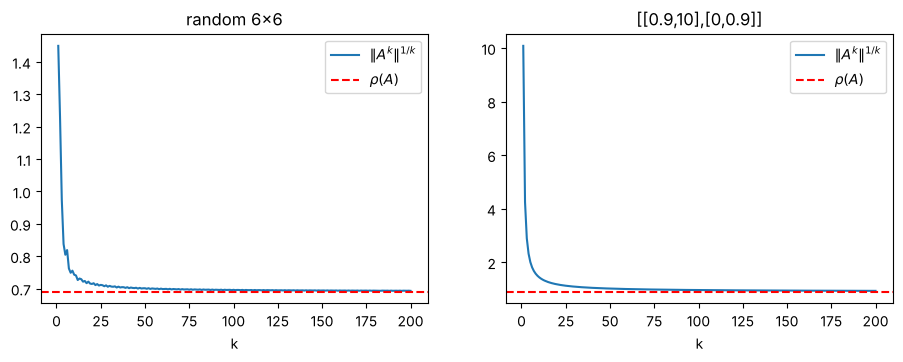

c =     1: max_k ||A^k|| =        3.9 at k = 9
c =    10: max_k ||A^k|| =       38.7 at k = 9
c =   100: max_k ||A^k|| =      387.4 at k = 9
c =  1000: max_k ||A^k|| =     3874.2 at k = 9


In [2]:
A1 = rng.standard_normal((6, 6)) / 2.5
A2 = np.array([[0.9, 10.0], [0.0, 0.9]])
ks = np.arange(1, 201)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a, A, name in [(ax[0], A1, "random 6x6"), (ax[1], A2, "[[0.9,10],[0,0.9]]")]:
    rho = max(abs(np.linalg.eigvals(A)))
    vals = [np.linalg.norm(np.linalg.matrix_power(A, k), 2) ** (1 / k) for k in ks]
    a.plot(ks, vals, label="$\\|A^k\\|^{1/k}$"); a.axhline(rho, color="r", ls="--", label="$\\rho(A)$")
    a.set_title(name); a.set_xlabel("k"); a.legend()
plt.show()
for c in [1, 10, 100, 1000]:
    A = np.array([[0.9, c], [0.0, 0.9]])
    norms = [np.linalg.norm(np.linalg.matrix_power(A, k), 2) for k in range(200)]
    print(f"c = {c:5d}: max_k ||A^k|| = {max(norms):10.1f} at k = {int(np.argmax(norms))}")

The peak is proportional to $c$ (it is about $c\cdot\max_kk\,0.9^{k-1}\approx3.87c$), while the eigenvalues do not depend on $c$ at all. The convergence of $\|A^k\|^{1/k}$ is slow for the non-normal matrix: after $200$ steps it is still visibly above $0.9$.

### P12.2
**How to find it.** `scipy.linalg.expm` computes the matrix exponential.

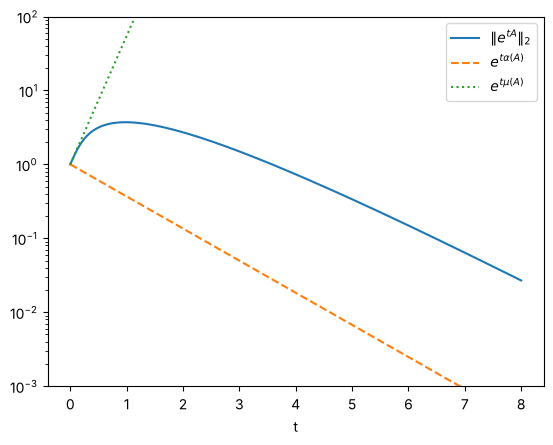

alpha(A) = -1.0, mu(A) = 4.0, peak of ||e^tA|| = 3.72 at t = 0.96


In [3]:
A = np.array([[-1.0, 10.0], [0.0, -1.0]])
ts = np.linspace(0, 8, 200)
norms = [np.linalg.norm(scipy.linalg.expm(t * A), 2) for t in ts]
alpha = max(np.linalg.eigvals(A).real); mu = np.linalg.eigvalsh((A + A.T) / 2).max()
plt.semilogy(ts, norms, label="$\\|e^{tA}\\|_2$")
plt.semilogy(ts, np.exp(alpha * ts), "--", label="$e^{t\\alpha(A)}$")
plt.semilogy(ts, np.exp(mu * ts), ":", label="$e^{t\\mu(A)}$")
plt.ylim(1e-3, 1e2); plt.legend(); plt.xlabel("t"); plt.show()
print(f"alpha(A) = {alpha}, mu(A) = {mu}, peak of ||e^tA|| = {max(norms):.2f} at t = {ts[int(np.argmax(norms))]:.2f}")

The norm starts with slope $\mu(A)=4$, peaks near $t=1$ at about $3.7$ (the corner entry is $10te^{-t}$), and only then follows $e^{-t}$.

### P12.3
**How to find it.** `solve_continuous_lyapunov(a, q)` solves $aX+Xa^{\mathsf H}=q$, so we pass $a=A^{\mathsf T}$ and $q=-I$. For the integral, the trapezoidal rule on $[0,40]$ is plenty for a matrix with $\alpha(A)\le-0.5$.

In [4]:
agree, stable_count = 0, 0
N = 3000
for _ in range(N):
    A = rng.standard_normal((5, 5)) - 1.2 * np.eye(5)
    stable = max(np.linalg.eigvals(A).real) < 0
    P = scipy.linalg.solve_continuous_lyapunov(A.T, -np.eye(5))
    pd = np.linalg.eigvalsh((P + P.T) / 2).min() > 0
    agree += (stable == pd); stable_count += stable
print(f"{stable_count} of {N} random matrices stable; Lyapunov test agrees in {agree} cases")

while True:
    A = rng.standard_normal((4, 4)) - 2 * np.eye(4)
    if max(np.linalg.eigvals(A).real) < -0.5: break
P = scipy.linalg.solve_continuous_lyapunov(A.T, -np.eye(4))
ts = np.linspace(0, 40, 8001)
vals = np.array([scipy.linalg.expm(t * A.T) @ scipy.linalg.expm(t * A) for t in ts[::10]])
integral = scipy.integrate.trapezoid(vals, ts[::10], axis=0)
print("integral formula vs solver: max difference", np.abs(integral - P).max().round(6))

zeta = 0.3
Aosc = np.array([[0, 1], [-1, -2 * zeta]])
Posc = scipy.linalg.solve_continuous_lyapunov(Aosc.T, -np.eye(2))
print("oscillator: P =", Posc.round(4).tolist(), " formula:", [[zeta + 1 / (2 * zeta), 0.5], [0.5, 1 / (2 * zeta)]])

878 of 3000 random matrices stable; Lyapunov test agrees in 3000 cases
integral formula vs solver: max difference 0.001295
oscillator: P = [[1.9667, 0.5], [0.5, 1.6667]]  formula: [[1.9666666666666668, 0.5], [0.5, 1.6666666666666667]]


The two tests agree on every matrix: positive definiteness of the Lyapunov solution is an eigenvalue-free stability test. (The trapezoidal rule with step $0.05$ is accurate to a few digits here.)

### P12.4
**How to find it.** All four methods use one multiplication by $A$ per step. The Chebyshev iteration uses the three-term recurrence (Saad, Algorithm 12.1): with $\theta=\frac{L+m}2$, $\delta=\frac{L-m}2$, $\sigma=\theta/\delta$, set $\rho_0=1/\sigma$, $d_0=r_0/\theta$, and then $\rho_k=1/(2\sigma-\rho_{k-1})$, $d_k=\rho_k\rho_{k-1}d_{k-1}+\frac{2\rho_k}\delta r_k$, $x_{k+1}=x_k+d_k$.

In [5]:
n, m_, L_ = 400, 1.0, 1000.0
Q, _ = np.linalg.qr(rng.standard_normal((n, n)))
eigs = np.concatenate([[m_, L_], m_ + (L_ - m_) * rng.random(n - 2)])
A = (Q * eigs) @ Q.T
xstar = rng.standard_normal(n); b = A @ xstar; x0 = np.zeros(n)
err0 = np.linalg.norm(x0 - xstar); tol = 1e-8; kappa = L_ / m_

def gd():
    x = x0.copy(); eta = 2 / (m_ + L_)
    for k in range(1, 100000):
        x = x - eta * (A @ x - b)
        if np.linalg.norm(x - xstar) < tol * err0: return k

def chebyshev():
    theta, delta = (L_ + m_) / 2, (L_ - m_) / 2; sigma = theta / delta
    x = x0.copy(); r = b - A @ x; rho = 1 / sigma; d = r / theta
    for k in range(1, 100000):
        x = x + d; r = r - A @ d
        if np.linalg.norm(x - xstar) < tol * err0: return k
        rho_new = 1 / (2 * sigma - rho)
        d = rho_new * rho * d + 2 * rho_new / delta * r; rho = rho_new

def heavy_ball():
    alpha = 4 / (math.sqrt(L_) + math.sqrt(m_)) ** 2
    beta = ((math.sqrt(kappa) - 1) / (math.sqrt(kappa) + 1)) ** 2
    x_prev = x0.copy(); x = x0.copy()
    for k in range(1, 100000):
        x, x_prev = x - alpha * (A @ x - b) + beta * (x - x_prev), x
        if np.linalg.norm(x - xstar) < tol * err0: return k

def cg():
    x = x0.copy(); r = b - A @ x; p = r.copy(); rr = r @ r
    for k in range(1, 100000):
        Ap = A @ p; a = rr / (p @ Ap); x = x + a * p; r = r - a * Ap
        if np.linalg.norm(x - xstar) < tol * err0: return k
        rr_new = r @ r; p = r + rr_new / rr * p; rr = rr_new

print(f"kappa = {kappa:.0f}; predictions: kappa/2 * ln(1e8) = {kappa / 2 * math.log(1e8):.0f}, sqrt(kappa)/2 * ln(2e8) = {math.sqrt(kappa) / 2 * math.log(2e8):.0f}")
for name, f in [("gradient descent", gd), ("Chebyshev", chebyshev), ("heavy ball", heavy_ball), ("conjugate gradient", cg)]:
    print(f"{name:20s} {f():6d} iterations")

kappa = 1000; predictions: kappa/2 * ln(1e8) = 9210, sqrt(kappa)/2 * ln(2e8) = 302


gradient descent       7965 iterations
Chebyshev               297 iterations
heavy ball              321 iterations
conjugate gradient      107 iterations


Gradient descent needs close to the worst-case $\frac\kappa2\ln10^8\approx9200$ iterations (a little fewer, since a random starting error has little weight on the slowest eigenvector); Chebyshev and the heavy ball about $\frac{\sqrt\kappa}2\ln(2\cdot10^8)\approx300$ (the heavy ball a little more, because of its transient). Conjugate gradients, which adapts to the actual eigenvalues and the actual starting error, needs about three times fewer still, and on clustered spectra it gains enormously more.

### P12.5
**How to find it.** For the double integrator $e^{\tau A}=\bigl(\begin{smallmatrix}1&\tau\\0&1\end{smallmatrix}\bigr)$, so $e^{\tau A}B=\binom\tau1$ and $W_T=\int_0^T\binom\tau1(\tau\ 1)\,d\tau=\bigl(\begin{smallmatrix}T^3/3&T^2/2\\T^2/2&T\end{smallmatrix}\bigr)$.

state reached at time T: [ 1. -0.]  target: [1. 0.]
control u(s) = [1.5, 0.75, 0.0, -0.75, -1.5] (linear in s: push, then brake)


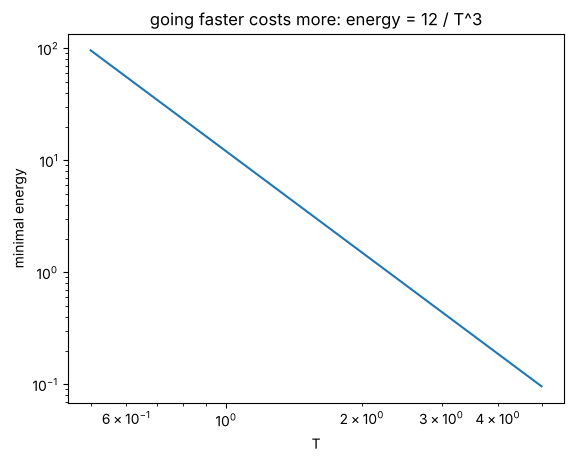

oscillator: 2
x'=-x+u, y'=-2y+u: 2
x'=-x+u, y'=-y+u: 1


In [6]:
A = np.array([[0.0, 1.0], [0.0, 0.0]]); B = np.array([[0.0], [1.0]])
def W(T): return np.array([[T**3 / 3, T**2 / 2], [T**2 / 2, T]])
T = 2.0; xT = np.array([1.0, 0.0]); w = np.linalg.solve(W(T), xT)
u = lambda s: (B.T @ scipy.linalg.expm((T - s) * A.T) @ w).item()
# simulate with small Euler steps
x = np.zeros(2); dt = 1e-4
for s in np.arange(0, T, dt):
    x = x + dt * (A @ x + B[:, 0] * u(s + dt / 2))
print("state reached at time T:", x.round(4), " target:", xT)
print("control u(s) =", [round(u(s), 3) for s in np.linspace(0, T, 5)], "(linear in s: push, then brake)")
Ts = np.linspace(0.5, 5, 50)
plt.loglog(Ts, [xT @ np.linalg.solve(W(t), xT) for t in Ts]); plt.xlabel("T"); plt.ylabel("minimal energy")
plt.title("going faster costs more: energy = 12 / T^3"); plt.show()

def kalman_rank(A, B):
    n = A.shape[0]
    return np.linalg.matrix_rank(np.hstack([np.linalg.matrix_power(A, j) @ B for j in range(n)]))
print("oscillator:", kalman_rank(np.array([[0, 1], [-1, 0.0]]), np.array([[0], [1.0]])))
print("x'=-x+u, y'=-2y+u:", kalman_rank(np.diag([-1.0, -2.0]), np.array([[1.0], [1.0]])))
print("x'=-x+u, y'=-y+u:", kalman_rank(-np.eye(2), np.array([[1.0], [1.0]])))

The minimal-energy control is affine in time: accelerate, then decelerate symmetrically, and the energy $x_T^{\mathsf T}W_T^{-1}x_T=12/T^3$ explodes for short horizons. The ranks are $2$, $2$ and $1$, as found in Exercise 12.8.

### P12.6
**How to find it.** `np.roots` for each cubic; the criterion is four inequalities. Disagreements can only come from cubics with a root extremely close to the imaginary axis.

In [7]:
N = 100000
abc = rng.standard_normal((N, 3)) * 3
by_roots = np.array([max(np.roots([1, a, b, c]).real) < 0 for a, b, c in abc])
a, b, c = abc.T
by_maxwell = (a > 0) & (b > 0) & (c > 0) & (a * b > c)
print(f"stable: {by_roots.sum()} of {N};  disagreements between roots and Maxwell: {(by_roots != by_maxwell).sum()}")
for coeffs in ([1, 1, 2, 8], [1, 3, 3, 1], [1, 2, 1, 2]):
    print(coeffs, "roots:", np.round(np.roots(coeffs), 4))

stable: 7591 of 100000;  disagreements between roots and Maxwell: 0
[1, 1, 2, 8] roots: [-2. +0.j      0.5+1.9365j  0.5-1.9365j]
[1, 3, 3, 1] roots: [-1.+0.j -1.-0.j -1.+0.j]
[1, 2, 1, 2] roots: [-2.+0.j  0.+1.j  0.-1.j]


No disagreements. The cubic $s^3+s^2+2s+8$ has roots $-2$ and $0.5\pm1.94i$: unstable, as $ab=2<8=c$. The boundary case $s^3+2s^2+s+2$ has roots $-2,\pm i$: a governor at the edge of hunting.